## Ejercicio 1

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

from lista4.data import load_csv
from lista4.models import fit_linear
from lista4.metrics import empirical_risk_squared

pd.set_option("display.float_format", lambda v: f"{v:,.6f}")

df1 = load_csv("experimento_1.csv")
df1.head()

,x1,x2,y
0,0.304717,1.727350,1.429562
1,-1.039984,-1.533861,-3.697491
2,0.750451,0.863828,3.525801
3,0.940565,-0.328525,2.194107
4,-1.951035,-0.061324,-6.489721


A. Construya una tabla con una fila por modelo. Incluya el intercepto, los coeficientes y el riesgo
empírico, y muéstrela en el cuaderno.

In [4]:
# Ajustar modelos
modelos = {
    "x1 -> y":        fit_linear(df1, ["x1"]),
    "x2 -> y":        fit_linear(df1, ["x2"]),
    "(x1, x2) -> y":  fit_linear(df1, ["x1", "x2"]),
}

riesgos = {k: empirical_risk_squared(df1["y"], m.predict(df1[m.feature_names]))
           for k, m in modelos.items()}

filas = []
for nombre, m in modelos.items():
    fila = {"modelo": nombre, "intercepto": m.intercept}
    for col, c in zip(m.feature_names, m.coefs):
        fila[f"coef_{col}"] = c
    fila["R_empirico"] = riesgos[nombre]
    filas.append(fila)

tabla_a = pd.DataFrame(filas)
tabla_a

,modelo,intercepto,coef_x1,R_empirico,coef_x2
0,x1 -> y,-0.082506,2.920460,1.020069,NaN
1,x2 -> y,-0.202971,NaN,8.374587,-0.044049
2,"(x1, x2) -> y",-0.083790,2.925130,1.002351,-0.131194


B.  Calcule corr(x1, y), corr(x2, y), corr(x1, x2).

In [5]:
corr_x1_y = df1["x1"].corr(df1["y"])
corr_x2_y = df1["x2"].corr(df1["y"])
corr_x1_x2 = df1["x1"].corr(df1["x2"])

pd.DataFrame({
    "corr(x1, y)":  [corr_x1_y],
    "corr(x2, y)":  [corr_x2_y],
    "corr(x1, x2)": [corr_x1_x2],
})

,"corr(x1, y)","corr(x2, y)","corr(x1, x2)"
0,0.937136,-0.015450,0.032563


C. Haga dos gráficas: y contra x1 y y contra x2. En cada gráfica incluya la recta ajustada por el
modelo correspondiente.

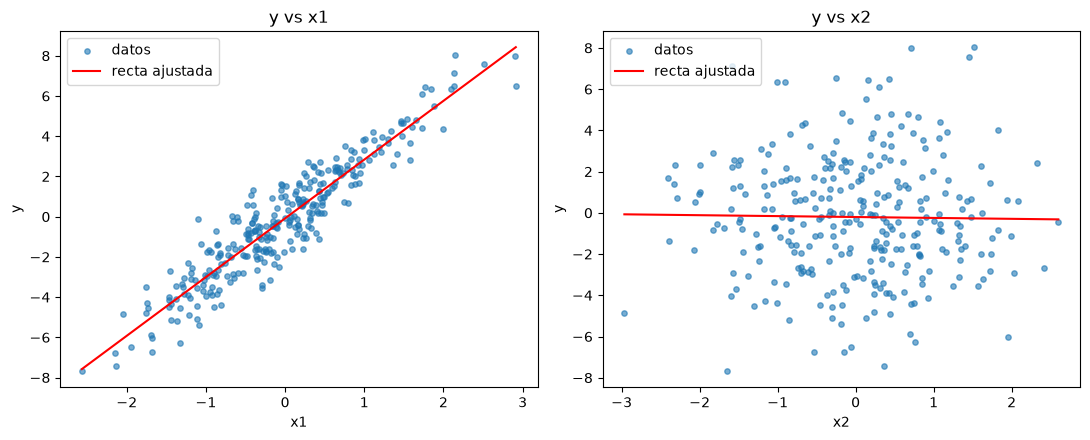

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# y vs x1
axes[0].scatter(df1["x1"], df1["y"], s=15, alpha=0.6, label="datos")
xs = np.linspace(df1["x1"].min(), df1["x1"].max(), 100)
m1 = modelos["x1 -> y"]
axes[0].plot(xs, m1.intercept + m1.coefs[0] * xs, color="red", label="recta ajustada")
axes[0].set_xlabel("x1"); axes[0].set_ylabel("y")
axes[0].set_title("y vs x1"); axes[0].legend()

# y vs x2
axes[1].scatter(df1["x2"], df1["y"], s=15, alpha=0.6, label="datos")
xs = np.linspace(df1["x2"].min(), df1["x2"].max(), 100)
m2 = modelos["x2 -> y"]
axes[1].plot(xs, m2.intercept + m2.coefs[0] * xs, color="red", label="recta ajustada")
axes[1].set_xlabel("x2"); axes[1].set_ylabel("y")
axes[1].set_title("y vs x2"); axes[1].legend()

plt.tight_layout(); plt.show()

D. Si solo pudiera conservar una de las dos variables, use como criterio el menor riesgo empírico
entre los dos modelos de una sola variable. Indique cuál conservaría.

In [7]:
mejor = min(("x1 -> y", "x2 -> y"), key=lambda k: riesgos[k])
print(f"Se conservaría: {mejor}  (R = {riesgos[mejor]:.6f})")

Se conservaría: x1 -> y  (R = 1.020069)
